# Highway Networks on CIFAR-10 (PyTorch)

**Task:** *Implement a 20-layer Highway Network and train it on the CIFAR-10 dataset.*

Based on:
> R. K. Srivastava, K. Greff, J. Schmidhuber, **"Highway Networks"**, arXiv:1505.00387v2, 2015 (ICML Workshop)



### Environment & Device Verification

In [ ]:
import torch
print(f"PyTorch version: {torch.__version__}")
device = torch.device("cuda" if torch.cuda.is_available() else ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu"))
print(f"Active compute device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))


PyTorch version: 2.11.0+cu130
Active compute device: cuda (Tesla T4)


### Library Imports & Dependencies

In [ ]:
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

## 1. CIFAR-10 Data Loading & Partitioning Pipeline
Prepares the CIFAR-10 dataset (50,000 training and 10,000 test 32x32 color images across 10 balanced classes):
* **Data Augmentation:** Standard random 4-pixel reflective padding crop and random horizontal flip to prevent overfitting on 32x32 imagery.
* **Normalization:** Standard per-channel mean $(0.4914, 0.4822, 0.4465)$ and standard deviation $(0.2470, 0.2435, 0.2616)$.
* **Dataset Partitioning:** Deterministic split of the 50,000 training images into 45,000 training and 5,000 validation samples (using fixed random seed 42).


In [3]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)
CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

def get_dataloaders(val_split=5000, batch_size=128, smoke=False, seed=42):
    """Prepares CIFAR-10 DataLoaders with standard random-translation & flip augmentation."""
    train_transform = transforms.Compose([
        transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
    ])
    test_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
    ])

    # Locate dataset root: torchvision expects the folder containing 'cifar-10-batches-py'
    data_dir = "." if (Path(".") / "cifar-10-batches-py").is_dir() else (
        ".." if (Path("..") / "cifar-10-batches-py").is_dir() else "./data"
    )
    full_train = datasets.CIFAR10(root=data_dir, train=True, download=True, transform=train_transform)
    val_set    = datasets.CIFAR10(root=data_dir, train=True, download=True, transform=test_transform)
    test_set   = datasets.CIFAR10(root=data_dir, train=False, download=True, transform=test_transform)

    val_n = val_split if not smoke else 256
    rng = np.random.RandomState(seed)
    perm = rng.permutation(len(full_train))
    val_idx, tr_idx = perm[:val_n], perm[val_n:]

    train_ds = Subset(full_train, tr_idx if not smoke else tr_idx[:512])
    val_ds   = Subset(val_set, val_idx if not smoke else val_idx[:256])
    test_ds  = Subset(test_set, range(len(test_set)) if not smoke else range(256))

    num_workers = 0 if smoke else 2
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=torch.cuda.is_available())
    val_loader   = DataLoader(val_ds, batch_size=batch_size * 2, shuffle=False, num_workers=num_workers, pin_memory=torch.cuda.is_available())
    test_loader  = DataLoader(test_ds, batch_size=batch_size * 2, shuffle=False, num_workers=num_workers, pin_memory=torch.cuda.is_available())

    print(f"Data partition: {len(train_ds):,} train | {len(val_ds):,} validation | {len(test_ds):,} test samples")
    return train_loader, val_loader, test_loader


## 2. 20-Layer Highway Network Architecture
Implements the multi-stage 20-layer Highway Network:
* **Highway Block (Equation 3):**
  $$y = H(x, W_H) \cdot T(x, W_T) + x \cdot (1 - T(x, W_T))$$
  where $H(x)$ applies $3\times3$ convolution with ReLU, and $T(x)$ applies $1\times1$ convolution with Sigmoid activation.
* **Carry Mode Initialization:** The transform gate bias is initialized to $b_T = -2.0$ ($\sigma(-2.0) \approx 0.119$). This biases each layer towards passing information unmodified ($1 - T(x) \approx 0.881$), enabling unimpeded gradient flow through 20 layers from the very first epoch.
* **3-Stage Multi-Resolution Topology:** 20 Highway layers organized into 3 spatial resolution stages with stride-2 transitions:
  $$\text{Stage 1 (32x32, 24 ch): 7 layers} \to \text{Stage 2 (16x16, 48 ch): 7 layers} \to \text{Stage 3 (8x8, 96 ch): 6 layers}$$
  Totaling exactly $7 + 7 + 6 = 20$ Highway layers (~810k parameters).
* **Gate Activity Profiling:** `get_gate_activity()` records average activations of all 20 transform gates across test batches for empirical verification of Figure 2.


In [4]:
class HighwayBlock(nn.Module):
    """
    Convolutional Highway Layer (Equation 3):
        y = H(x) * T(x) + x * (1 - T(x))
    """
    def __init__(self, channels, gate_bias=-2.0, bn=False):
        super().__init__()
        self.conv_h = nn.Conv2d(channels, channels, 3, padding=1, bias=True)
        self.bn_h   = nn.BatchNorm2d(channels) if bn else None
        self.conv_t = nn.Conv2d(channels, channels, 1, bias=True)
        self.act    = nn.ReLU(inplace=True)

        nn.init.kaiming_normal_(self.conv_h.weight, nonlinearity="relu")
        nn.init.zeros_(self.conv_h.bias)
        nn.init.kaiming_normal_(self.conv_t.weight, nonlinearity="sigmoid")
        nn.init.constant_(self.conv_t.bias, gate_bias)
        self.last_t = None

    def forward(self, x):
        h = self.conv_h(x)
        if self.bn_h is not None:
            h = self.bn_h(h)
        h = self.act(h)
        t = torch.sigmoid(self.conv_t(x))
        self.last_t = t.detach()
        return h * t + x * (1.0 - t)


class HighwayCNN(nn.Module):
    """
    20-Layer Multi-Stage Highway Network (Section 6.2 of Srivastava et al., 2015):
      * 3 convolutional stages with stride=2 transitions:
        32x32 (base) -> 16x16 (2*base) -> 8x8 (4*base) -> Global Average Pooling.
      * 20 Highway layers: stages = (7, 7, 6) -> 7 + 7 + 6 = 20 layers.
    """
    def __init__(self, stages=(7, 7, 6), base=24, num_classes=10, gate_bias=-2.0, bn=False):
        super().__init__()
        self.stages = stages
        self.depth = sum(stages)
        self.stem = nn.Sequential(
            nn.Conv2d(3, base, 3, padding=1, bias=True),
            nn.BatchNorm2d(base) if bn else nn.Identity(),
            nn.ReLU(inplace=True)
        )
        nn.init.kaiming_normal_(self.stem[0].weight, nonlinearity="relu")

        # Stage 1: 32x32
        c1 = base
        self.stage1 = nn.Sequential(*[HighwayBlock(c1, gate_bias=gate_bias, bn=bn) for _ in range(stages[0])])

        # Transition 1 -> 2 (stride 2)
        c2 = base * 2
        self.trans1 = nn.Sequential(
            nn.Conv2d(c1, c2, 3, stride=2, padding=1, bias=True),
            nn.BatchNorm2d(c2) if bn else nn.Identity(),
            nn.ReLU(inplace=True)
        )
        nn.init.kaiming_normal_(self.trans1[0].weight, nonlinearity="relu")

        # Stage 2: 16x16
        self.stage2 = nn.Sequential(*[HighwayBlock(c2, gate_bias=gate_bias, bn=bn) for _ in range(stages[1])])

        # Transition 2 -> 3 (stride 2)
        c3 = base * 4
        self.trans2 = nn.Sequential(
            nn.Conv2d(c2, c3, 3, stride=2, padding=1, bias=True),
            nn.BatchNorm2d(c3) if bn else nn.Identity(),
            nn.ReLU(inplace=True)
        )
        nn.init.kaiming_normal_(self.trans2[0].weight, nonlinearity="relu")

        # Stage 3: 8x8
        self.stage3 = nn.Sequential(*[HighwayBlock(c3, gate_bias=gate_bias, bn=bn) for _ in range(stages[2])])

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc   = nn.Linear(c3, num_classes)
        nn.init.xavier_uniform_(self.fc.weight)
        nn.init.zeros_(self.fc.bias)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.trans1(x)
        x = self.stage2(x)
        x = self.trans2(x)
        x = self.stage3(x)
        return self.fc(self.pool(x).flatten(1))

    @torch.no_grad()
    def get_gate_activity(self, loader, device, max_batches=8):
        """Measures average gate activation T(x) across all 20 Highway layers (Figure 2)."""
        self.eval()
        highway_blocks = [m for stage in (self.stage1, self.stage2, self.stage3) for m in stage if isinstance(m, HighwayBlock)]
        sums = [0.0] * len(highway_blocks)
        n = 0
        for xb, _ in loader:
            xb = xb.to(device)
            self(xb)
            for i, blk in enumerate(highway_blocks):
                if blk.last_t is not None:
                    sums[i] += float(blk.last_t.mean())
            n += 1
            if n >= max_batches: break
        return [s / n for s in sums] if n > 0 else None


## 3. Evaluation & Optimization Routines
Defines the training, evaluation, and checkpointing routines:
* **`evaluate()`:** Computes exact Cross-Entropy loss and top-1 accuracy over any dataset loader under `torch.no_grad()`.
* **`train_highway()`:** Trains the model using SGD with Nesterov momentum ($\mu = 0.9$), weight decay ($5 \cdot 10^{-4}$), and a Cosine Annealing learning rate schedule over 50 epochs. Automatically checkpoints the best model state based on peak validation accuracy and evaluates the best model on the holdout test set.


In [5]:
@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    total_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss = criterion(out, yb)
        total_loss += float(loss) * len(yb)
        correct    += int((out.argmax(1) == yb).sum())
        total      += len(yb)
    return total_loss / total, correct / total

def train_highway(model, train_loader, val_loader, test_loader, cfg, device, out_dir):
    """Trains the model, checkpoints on validation accuracy, and tests the best model."""
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=cfg["momentum"], weight_decay=cfg["weight_decay"], nesterov=True)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg["epochs"], eta_min=1e-5)

    hist = {"epochs": [], "params": sum(p.numel() for p in model.parameters())}
    best_val_acc, best_ep, best_state = 0.0, 0, None
    t0 = time.time()

    print(f"Training started: {cfg['epochs']} epochs | lr={cfg['lr']} | parameters={hist['params']:,}")

    for ep in range(1, cfg["epochs"] + 1):
        model.train()
        tr_loss, tr_ok, tr_n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            tr_loss += float(loss.detach()) * len(yb)
            tr_ok   += int((out.argmax(1) == yb).sum())
            tr_n    += len(yb)

        scheduler.step()
        val_loss, val_acc = evaluate(model, val_loader, device)
        lr_now = optimizer.param_groups[0]["lr"]

        hist["epochs"].append({
            "epoch": ep, "train_loss": tr_loss / tr_n, "train_acc": tr_ok / tr_n,
            "val_loss": val_loss, "val_acc": val_acc, "lr": lr_now, "time": time.time() - t0
        })

        marker = ""
        if val_acc > best_val_acc:
            best_val_acc, best_ep = val_acc, ep
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, out_dir / "model_highway_best.pth")
            marker = " *"

        print(f"Epoch {ep:2d}/{cfg['epochs']} | train loss: {tr_loss/tr_n:.4f} | train acc: {tr_ok/tr_n:.2%} | val loss: {val_loss:.4f} | val acc: {val_acc:.2%}{marker}")

    # Load best checkpoint and evaluate on test set
    if best_state is not None:
        model.load_state_dict(best_state)
    test_loss, test_acc = evaluate(model, test_loader, device)
    print(f"\nTraining complete! Best validation epoch: {best_ep} ({best_val_acc:.2%})")
    print(f"FINAL TEST SET ACCURACY: {test_acc:.2%} (test loss: {test_loss:.4f})")

    hist["best_val_acc"], hist["best_epoch"] = best_val_acc, best_ep
    hist["test_acc"], hist["test_loss"] = test_acc, test_loss
    with open(out_dir / "training_history.json", "w", encoding="utf-8") as f:
        json.dump(hist, f, indent=2)
    return hist


## 4. Scientific Visualization & Diagnostic Functions
Defines publication-quality plotting functions:
* **`plot_dataset_preview()`:** Displays a 2x5 grid of unnormalized CIFAR-10 training samples with ground-truth class labels.
* **`plot_curves()`:** Reproduces Figure 1 of the paper — dual-panel plots of loss convergence (logarithmic scale) and accuracy progression across 50 epochs.
* **`plot_gate_activity()`:** Reproduces Figure 2 of the paper — a 20-bar histogram showing the mean transform gate activation $T(x)$ across all 20 Highway layers relative to the initial $b_T = -2.0$ reference line.
* **`plot_prediction_gallery()`:** Qualitative analysis displaying a gallery of correct test predictions (green borders) alongside representative misclassifications (red borders) with predictive confidences.


In [6]:
def plot_dataset_preview(loader, out_dir, num_samples=10):
    for xb, yb in loader: break
    mean = torch.tensor(CIFAR_MEAN).view(1, 3, 1, 1)
    std  = torch.tensor(CIFAR_STD).view(1, 3, 1, 1)
    imgs = (xb[:num_samples] * std + mean).clamp(0, 1).permute(0, 2, 3, 1).numpy()

    fig, axes = plt.subplots(2, 5, figsize=(11, 4.5), constrained_layout=True)
    for i, ax in enumerate(axes.flat):
        if i < len(imgs):
            ax.imshow(imgs[i])
            ax.set_title(CIFAR_CLASSES[int(yb[i])], fontsize=10, pad=4)
        ax.axis("off")
    fig.suptitle("CIFAR-10 Dataset Samples", fontsize=12, fontweight="bold", y=1.02)
    fig.savefig(out_dir / "dataset_preview.png", dpi=140, bbox_inches="tight")
    try: plt.show()
    except Exception: pass
    plt.close(fig)

def plot_curves(hist, out_dir):
    eps = [e["epoch"] for e in hist["epochs"]]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
    ax[0].plot(eps, [e["train_loss"] for e in hist["epochs"]], color="#1f6feb", label="train loss")
    ax[0].plot(eps, [e["val_loss"] for e in hist["epochs"]], color="#ff7b00", linestyle="--", label="val loss")
    ax[0].set_yscale("log")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss (log scale)")
    ax[0].set_title("Optimization Loss — 20-Layer Highway (Figure 1)")
    ax[0].grid(alpha=0.3); ax[0].legend()

    ax[1].plot(eps, [100 * e["train_acc"] for e in hist["epochs"]], color="#1f6feb", label="train acc")
    ax[1].plot(eps, [100 * e["val_acc"] for e in hist["epochs"]], color="#238636", linestyle="--", label="val acc")
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy [%]")
    ax[1].set_title("Generalization Accuracy — 20-Layer Highway")
    ax[1].grid(alpha=0.3); ax[1].legend()

    fig.savefig(out_dir / "curves_highway_d20.png", dpi=140)
    try: plt.show()
    except Exception: pass
    plt.close(fig)

def plot_gate_activity(gates, out_dir, gate_bias=-2.0):
    if not gates: return
    layers = list(range(1, len(gates) + 1))
    fig, ax = plt.subplots(figsize=(10, 4.2), constrained_layout=True)
    ax.bar(layers, gates, color="#1f6feb", alpha=0.75, edgecolor="#0945ac", width=0.7)
    ax.plot(layers, gates, color="#0945ac", marker="o", markersize=4, linewidth=1.5)
    init_val = 1.0 / (1.0 + math.exp(-gate_bias))
    ax.axhline(init_val, color="#d9383a", linestyle="--", linewidth=1.2, label=f"Init σ(b_T={gate_bias:.1f}) ≈ {init_val:.3f}")
    ax.set_xlabel("Highway Layer Index (1 to 20)")
    ax.set_ylabel("Mean Gate Activation T(x)")
    ax.set_title("Transform Gate Activity Profile across 20 Layers (Figure 2)")
    ax.set_ylim(0, 1.0); ax.grid(alpha=0.3, axis="y"); ax.legend()
    fig.savefig(out_dir / "gates_highway_d20.png", dpi=140)
    try: plt.show()
    except Exception: pass
    plt.close(fig)

@torch.no_grad()
def plot_prediction_gallery(model, loader, device, out_dir, num_samples=8):
    model.eval()
    correct_list, error_list = [], []
    mean = torch.tensor(CIFAR_MEAN).view(1, 3, 1, 1)
    std  = torch.tensor(CIFAR_STD).view(1, 3, 1, 1)

    for xb, yb in loader:
        logits = model(xb.to(device))
        probs  = torch.softmax(logits, dim=1).cpu()
        preds  = probs.argmax(dim=1)
        xb_raw = (xb * std + mean).clamp(0, 1).permute(0, 2, 3, 1).numpy()
        for j in range(len(yb)):
            t_idx, p_idx, conf = int(yb[j]), int(preds[j]), float(probs[j, preds[j]])
            item = (xb_raw[j], t_idx, p_idx, conf)
            if t_idx == p_idx and len(correct_list) < num_samples: correct_list.append(item)
            elif t_idx != p_idx and len(error_list) < num_samples: error_list.append(item)
        if len(correct_list) >= num_samples and len(error_list) >= num_samples: break

    n = max(len(correct_list), len(error_list))
    if n == 0: return
    fig, axes = plt.subplots(2, n, figsize=(n * 2.0, 4.6), constrained_layout=True)
    for col in range(n):
        ax_c = axes[0, col]
        if col < len(correct_list):
            img, t_idx, _, conf = correct_list[col]
            ax_c.imshow(img)
            ax_c.set_title(f"{CIFAR_CLASSES[t_idx]}\n{conf:.1%}", fontsize=8, color="#1b7837", fontweight="bold")
            for s in ax_c.spines.values(): s.set_color("#1b7837"); s.set_linewidth(2)
        ax_c.set_xticks([]); ax_c.set_yticks([])

        ax_e = axes[1, col]
        if col < len(error_list):
            img, t_idx, p_idx, conf = error_list[col]
            ax_e.imshow(img)
            ax_e.set_title(f"pred: {CIFAR_CLASSES[p_idx]} ({conf:.0%})\ntrue: {CIFAR_CLASSES[t_idx]}", fontsize=8, color="#b2182b", fontweight="bold")
            for s in ax_e.spines.values(): s.set_color("#b2182b"); s.set_linewidth(2)
        ax_e.set_xticks([]); ax_e.set_yticks([])

    axes[0, 0].set_ylabel("CORRECT", fontsize=10, fontweight="bold", color="#1b7837", labelpad=8)
    axes[1, 0].set_ylabel("MISCLASSIFIED", fontsize=10, fontweight="bold", color="#b2182b", labelpad=8)
    fig.suptitle("Qualitative Evaluation: Test Set Predictions & Errors", fontsize=12, fontweight="bold", y=1.03)
    fig.savefig(out_dir / "predictions_gallery.png", dpi=140, bbox_inches="tight")
    try: plt.show()
    except Exception: pass
    plt.close(fig)


## 5. Experiment Configuration & Hyperparameters
Specifies the central configuration dictionary `CONFIG`:
* 20 Highway layers (`stages = [7, 7, 6]`),
* 24 base channels,
* 50 epochs with Cosine Annealing learning rate schedule,
* SGD with Nesterov momentum ($0.9$) and initial learning rate $0.1$,
* Initial transform gate bias $b_T = -2.0$,
* `bn = False` (no Batch Normalization),
* Output directory `./results`.


In [ ]:
CONFIG = {
    "stages":         [7, 7, 6],    # 7 + 7 + 6 = 20 highway layers
    "base_channels":  24,           # channels: 24 -> 48 -> 96 (~810k parameters)
    "epochs":         50,           # 50 epochs with Cosine Annealing learning rate schedule
    "batch_size":     128,
    "lr":             0.1,          # SGD with Nesterov momentum
    "momentum":       0.9,
    "weight_decay":   5e-4,
    "gate_bias":      -2.0,         # initial transform gate bias b_T (carry mode)
    "bn":             False,        # NO BatchNorm
    "val_split":      5000,         # 45,000 train / 5,000 validation / 10,000 test
    "smoke":          False,        # True = fast 10-second verification run
    "out_dir":        "./results",
}

out_dir = Path(CONFIG["out_dir"]).resolve()
out_dir.mkdir(parents=True, exist_ok=True)
print("Experiment Configuration Applied:")
for k, v in CONFIG.items():
    print(f"  {k:15s}: {v}")


Experiment Configuration Applied:
  stages         : [7, 7, 6]
  base_channels  : 24
  epochs         : 50
  batch_size     : 128
  lr             : 0.1
  momentum       : 0.9
  weight_decay   : 0.0005
  gate_bias      : -2.0
  bn             : False
  val_split      : 5000
  smoke          : False
  out_dir        : ./results


## 6. Dataset Loading & Visual Inspection
Executes the CIFAR-10 data preparation pipeline: creates `train_loader`, `val_loader`, and `test_loader`, prints partition sample counts, and renders the initial 10-sample CIFAR-10 dataset preview (`dataset_preview.png`).


Data partition: 45,000 train | 5,000 validation | 10,000 test samples


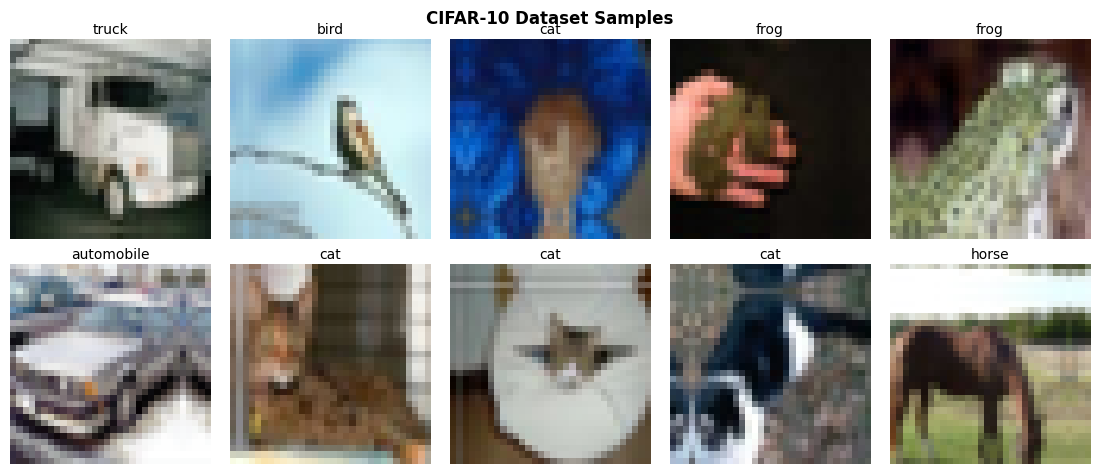

In [8]:
train_loader, val_loader, test_loader = get_dataloaders(
    val_split=CONFIG["val_split"],
    batch_size=CONFIG["batch_size"],
    smoke=CONFIG["smoke"]
)
plot_dataset_preview(train_loader, out_dir)


## 7. Model Instantiation & Training Execution
Instantiates the 20-layer `HighwayCNN` on the active compute device, prints the verified parameter count (810,346 parameters), and executes the 50-epoch training procedure. Tracks validation performance, saves the best model checkpoint (`model_highway_best.pth`), evaluates the final test set accuracy, and saves the history to `training_history.json`.


In [9]:
model = HighwayCNN(
    stages=CONFIG["stages"],
    base=CONFIG["base_channels"],
    gate_bias=CONFIG["gate_bias"],
    bn=CONFIG["bn"]
).to(device)

print(f"Model instantiated: 20-Layer HighwayCNN | Parameters: {sum(p.numel() for p in model.parameters()):,} | bn={CONFIG['bn']}")

hist = train_highway(model, train_loader, val_loader, test_loader, CONFIG, device, out_dir)


Model instantiated: 20-Layer HighwayCNN | Parameters: 810,346 | bn=False
Training started: 50 epochs | lr=0.1 | parameters=810,346
Epoch  1/50 | train loss: 1.9329 | train acc: 26.36% | val loss: 1.7258 | val acc: 34.62% *
Epoch  2/50 | train loss: 1.5750 | train acc: 41.75% | val loss: 1.5249 | val acc: 42.82% *
Epoch  3/50 | train loss: 1.3665 | train acc: 50.40% | val loss: 1.2099 | val acc: 56.02% *
Epoch  4/50 | train loss: 1.2118 | train acc: 56.72% | val loss: 1.1627 | val acc: 58.54% *
Epoch  5/50 | train loss: 1.0937 | train acc: 61.55% | val loss: 0.9796 | val acc: 64.86% *
Epoch  6/50 | train loss: 1.0187 | train acc: 64.34% | val loss: 0.9105 | val acc: 67.92% *
Epoch  7/50 | train loss: 0.9546 | train acc: 66.57% | val loss: 0.8731 | val acc: 67.98% *
Epoch  8/50 | train loss: 0.8873 | train acc: 68.74% | val loss: 0.7815 | val acc: 73.26% *
Epoch  9/50 | train loss: 0.8302 | train acc: 70.96% | val loss: 0.8742 | val acc: 70.28%
Epoch 10/50 | train loss: 0.7776 | train ac

## 8. Generation of Publication-Grade Visualizations
Generates and displays all visual diagnostics:
1. Loss convergence (logarithmic scale) and accuracy progression curves (`curves_highway_d20.png`, Figure 1).
2. Transform gate activity profile across all 20 Highway layers (`gates_highway_d20.png`, Figure 2).
3. Qualitative evaluation gallery comparing correct test predictions vs misclassifications (`predictions_gallery.png`).


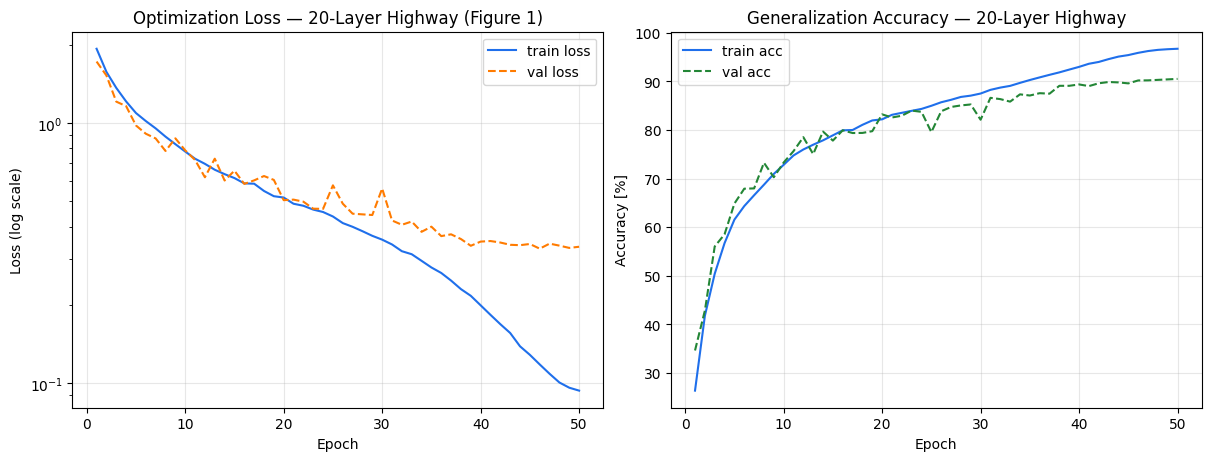

Mean transform gate T(x) activation across all 20 layers: 0.403


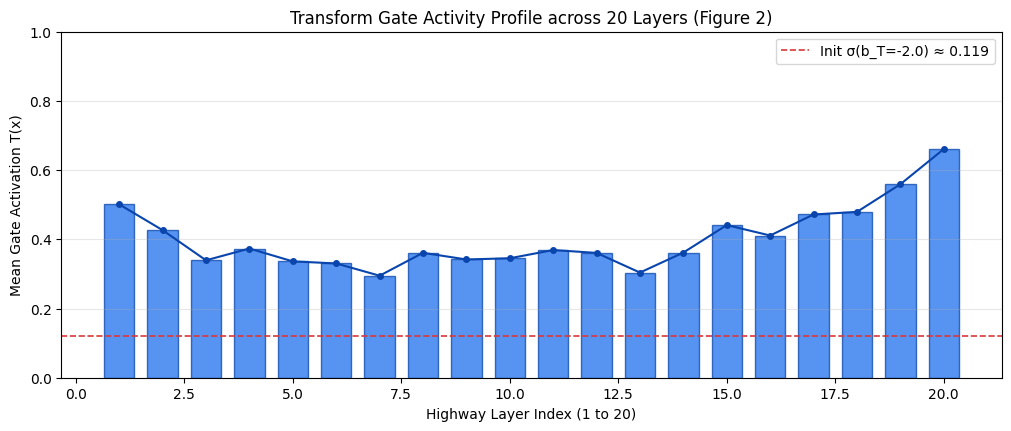

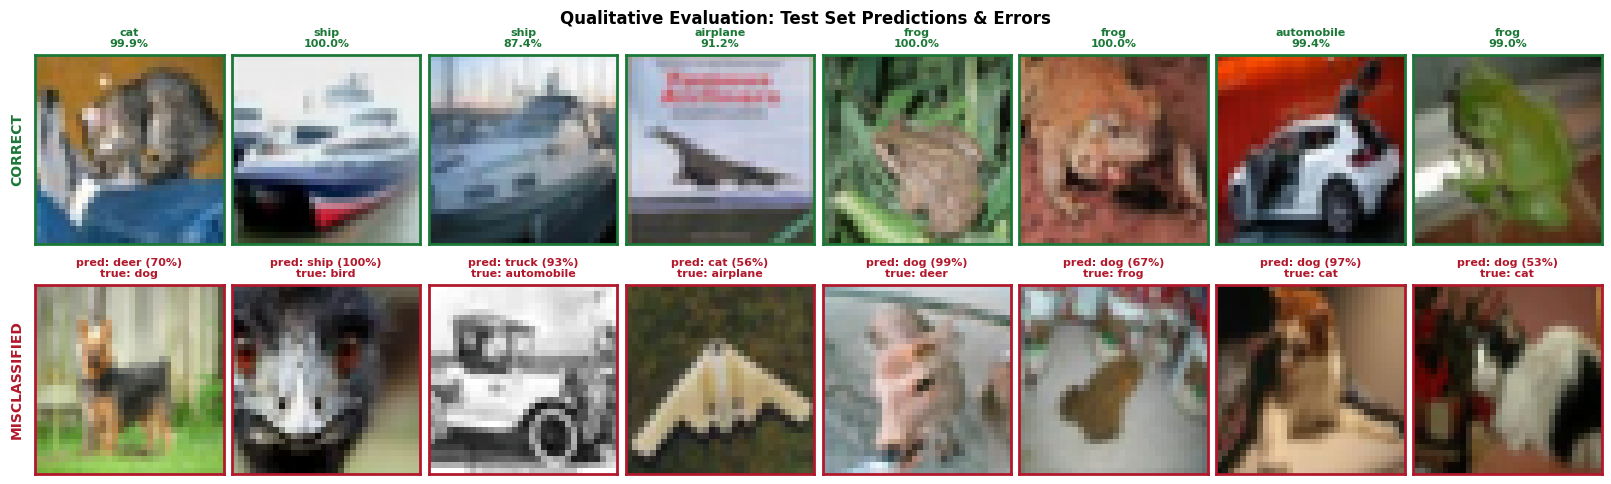

In [ ]:
plot_curves(hist, out_dir)

gates = model.get_gate_activity(test_loader, device)
if gates:
    print(f"Mean transform gate T(x) activation across all 20 layers: {np.mean(gates):.3f}")
    plot_gate_activity(gates, out_dir, gate_bias=CONFIG["gate_bias"])

plot_prediction_gallery(model, test_loader, device, out_dir, num_samples=8)


## 9. Packaging Results & Submission Archive

In [11]:
import shutil
zip_path = Path("results.zip")
shutil.make_archive("results", "zip", out_dir)
print(f"[OK] Results archive created: {zip_path.resolve()} ({zip_path.stat().st_size / 1024:.1f} KB)")
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    pass


[OK] Results archive created: /content/results.zip (3299.7 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>